## Practice: Basic Artificial Neural Networks
Credits: this notebook belongs to [Practical DL](https://docs.google.com/forms/d/e/1FAIpQLScvrVtuwrHSlxWqHnLt1V-_7h2eON_mlRR6MUb3xEe5x9LuoA/viewform?usp=sf_link) course by Yandex School of Data Analysis.

We will start working with neural networks on the practice session. Your homework will be to finish the implementation of the layers.

Our goal is simple, yet an actual implementation may take some time :). We are going to write an Artificial Neural Network (almost) from scratch. The software design was heavily inspired by [PyTorch](http://pytorch.org) which is the main framework of our course 

Speaking about the homework (once again, it will be really similar to this seminar), it requires sending **multiple** files, please do not forget to include all the files when sending to TA. The list of files:
- This notebook
- modules.ipynb with all blocks implemented (except maybe `Conv2d` and `MaxPool2d` layers implementation which are part of 'advanced' version of this homework)

In [40]:
%matplotlib inline
from time import time, sleep
import numpy as np
import matplotlib.pyplot as plt
from IPython import display

# Framework

Implement everything in `modules.ipynb`. Read all the comments thoughtfully to ease the pain. Please try not to change the prototypes.

Do not forget, that each module should return **AND** store `output` and `gradInput`.

The typical assumption is that `module.backward` is always executed after `module.forward`,
so `output` is stored, this would be useful for `SoftMax`. 

### Tech note
Prefer using `np.multiply`, `np.add`, `np.divide`, `np.subtract` instead of `*`,`+`,`/`,`-` for better memory handling.

Example: suppose you allocated a variable 

```
a = np.zeros(...)
```
So, instead of
```
a = b + c  # will be reallocated, GC needed to free
``` 
You can use: 
```
np.add(b,c,out = a) # puts result in `a`
```

In [41]:
# (re-)load layers
%run modules.ipynb

# Toy example

Use this example to debug your code, start with logistic regression and then test other layers. You do not need to change anything here. This code is provided for you to test the layers. Also it is easy to use this code in MNIST task.

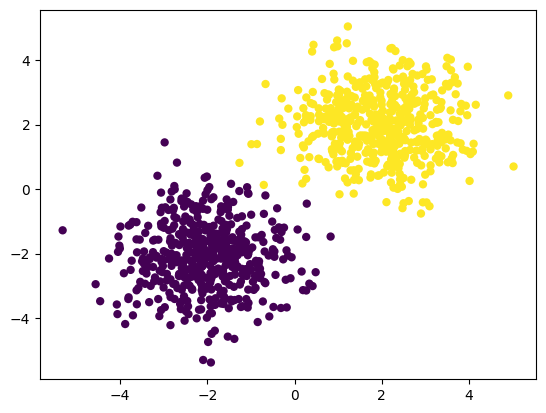

In [42]:
# Generate some data
N = 500

X1 = np.random.randn(N,2) + np.array([2,2])
X2 = np.random.randn(N,2) + np.array([-2,-2])

Y = np.concatenate([np.ones(N),np.zeros(N)])[:,None]
Y = np.hstack([Y, 1-Y])

X = np.vstack([X1,X2])
plt.scatter(X[:,0],X[:,1], c = Y[:,0], edgecolors= 'none')

Define a **logistic regression** for debugging. 

In [43]:
net = Sequential()
net.add(Linear(2, 2))
net.add(LogSoftMax())

criterion = ClassNLLCriterion()

print(net)

# Test something like that then 

# net = Sequential()
# net.add(Linear(2, 4))
# net.add(ReLU())
# net.add(Linear(4, 2))
# net.add(LogSoftMax())

Linear 2 -> 2
LogSoftMax



Start with batch_size = 1000 to make sure every step lowers the loss, then try stochastic version.

In [44]:
# Iptimizer params
optimizer_config = {'learning_rate' : 1e-1, 'momentum': 0.9}
optimizer_state = {}

# Looping params
n_epoch = 20
batch_size = 128

In [45]:
# batch generator
def get_batches(dataset, batch_size):
    X, Y = dataset
    n_samples = X.shape[0]
        
    # Shuffle at the start of epoch
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)
        
        batch_idx = indices[start:end]
    
        yield X[batch_idx], Y[batch_idx]

### Train

Basic training loop. Examine it.

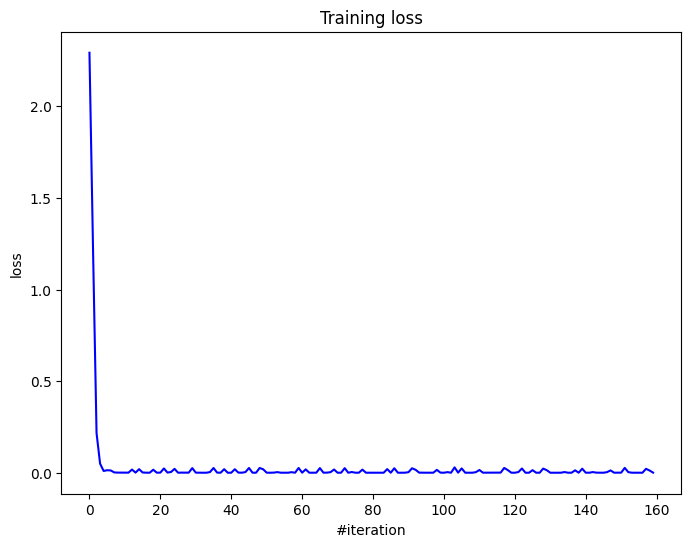

Current loss: 0.000523


In [46]:
loss_history = []

for i in range(n_epoch):
    for x_batch, y_batch in get_batches((X, Y), batch_size):
        
        net.zeroGradParameters()
        
        # Forward
        predictions = net.forward(x_batch)
        loss = criterion.forward(predictions, y_batch)
    
        # Backward
        dp = criterion.backward(predictions, y_batch)
        net.backward(x_batch, dp)
        
        # Update weights
        sgd_momentum(net.getParameters(), 
                     net.getGradParameters(), 
                     optimizer_config,
                     optimizer_state)      
        
        loss_history.append(loss)

    # Visualize
    display.clear_output(wait=True)
    plt.figure(figsize=(8, 6))
        
    plt.title("Training loss")
    plt.xlabel("#iteration")
    plt.ylabel("loss")
    plt.plot(loss_history, 'b')
    plt.show()
    
    print('Current loss: %f' % loss)    

# Digit classification 

We are using old good [MNIST](http://yann.lecun.com/exdb/mnist/) as our dataset. It can be downloaded with the following file.

In [47]:
# mnist.py уже лежит рядом с ноутбуком, скачивание не требуется.
# При необходимости (на macOS wget обычно нет) можно скачать так:
# !curl -LO https://raw.githubusercontent.com/girafe-ai/ml-course/23f_basic/homeworks/hw08_nn_from_scratch/mnist.py


In [48]:
import mnist
X_train, y_train, X_val, y_val, X_test, y_test = mnist.load_dataset()

One-hot encode the labels first.

In [49]:
# One-hot encoding of labels ---------------------------------------------
def one_hot(y, n_classes=10):
    out = np.zeros((len(y), n_classes), dtype=np.float32)
    out[np.arange(len(y)), y] = 1.0
    return out

Y_train = one_hot(y_train)
Y_val = one_hot(y_val)
Y_test = one_hot(y_test)

# ensure 2D features (N, 784)
X_train = X_train.reshape(len(X_train), -1)
X_val = X_val.reshape(len(X_val), -1)
X_test = X_test.reshape(len(X_test), -1)

# Общие параметры экспериментов
BATCH_SIZE = 128
EPOCHS_COMPARE = 8
EPOCHS_FINAL = 25

print("One-hot shapes:", Y_train.shape, Y_val.shape, Y_test.shape)


One-hot shapes: (50000, 10) (10000, 10) (10000, 10)


- **Compare** `ReLU`, `ELU`, `LeakyReLU`, `SoftPlus` activation functions. 
You would better pick the best optimizer params for each of them, but it is overkill for now. Use an architecture of your choice for the comparison.
- **Try** inserting `BatchNormalization` (folowed by `ChannelwiseScaling`) between `Linear` module and activation functions.
- Plot the losses both from activation functions comparison and `BatchNormalization` comparison on one plot. Please find a scale (log?) when the lines are distinguishable, do not forget about naming the axes, the plot should be goodlooking.
- Plot the losses for two networks: one trained by momentum_sgd, another one trained by Adam. Which one performs better?
- Hint: good logloss for MNIST should be around 0.5. 

[activation] ReLU
  epoch  1: loss=0.4761  val_acc=0.9321
  epoch  2: loss=0.2174  val_acc=0.9519
  epoch  3: loss=0.1558  val_acc=0.9608
  epoch  4: loss=0.1216  val_acc=0.9669
  epoch  5: loss=0.1003  val_acc=0.9710
  epoch  6: loss=0.0848  val_acc=0.9715
  epoch  7: loss=0.0733  val_acc=0.9729
  epoch  8: loss=0.0641  val_acc=0.9750
[activation] ELU
  epoch  1: loss=0.4658  val_acc=0.9196
  epoch  2: loss=0.2664  val_acc=0.9372
  epoch  3: loss=0.2022  val_acc=0.9506
  epoch  4: loss=0.1624  val_acc=0.9586
  epoch  5: loss=0.1360  val_acc=0.9650
  epoch  6: loss=0.1167  val_acc=0.9657
  epoch  7: loss=0.1018  val_acc=0.9696
  epoch  8: loss=0.0903  val_acc=0.9723
[activation] LeakyReLU
  epoch  1: loss=0.4769  val_acc=0.9308
  epoch  2: loss=0.2217  val_acc=0.9512
  epoch  3: loss=0.1602  val_acc=0.9594
  epoch  4: loss=0.1254  val_acc=0.9661
  epoch  5: loss=0.1035  val_acc=0.9714
  epoch  6: loss=0.0876  val_acc=0.9708
  epoch  7: loss=0.0760  val_acc=0.9732
  epoch  8: loss=0.066

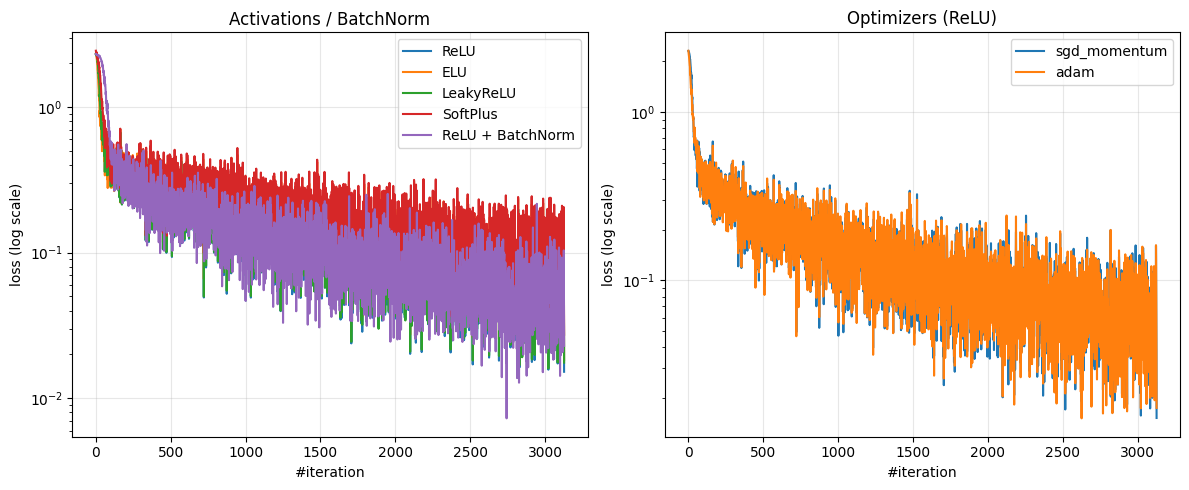

In [50]:
from sklearn.metrics import accuracy_score

def get_batches(dataset, batch_size):
    X, Y = dataset
    n_samples = X.shape[0]
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)
        yield X[indices[start:end]], Y[indices[start:end]]

def build_mlp(activation, n_hidden=128, use_bn=False):
    net = Sequential()
    net.add(Linear(784, n_hidden))
    if use_bn:
        net.add(BatchNormalization(alpha=0.9))
        net.add(ChannelwiseScaling(n_hidden))
    net.add(activation)
    net.add(Linear(n_hidden, 10))
    net.add(LogSoftMax())
    return net

def train_network(net, criterion, optimizer, optimizer_config, n_epoch,
                  batch_size=128, verbose=True):
    optimizer_state = {}
    loss_history, val_acc_history = [], []
    for epoch in range(n_epoch):
        net.train()
        epoch_loss, n_batches = 0.0, 0
        for x_batch, y_batch in get_batches((X_train, Y_train), batch_size):
            net.zeroGradParameters()
            pred = net.forward(x_batch)
            loss = criterion.forward(pred, y_batch)
            dp = criterion.backward(pred, y_batch)
            net.backward(x_batch, dp)
            optimizer(net.getParameters(), net.getGradParameters(),
                      optimizer_config, optimizer_state)
            loss_history.append(loss)
            epoch_loss += loss; n_batches += 1
        net.evaluate()
        val_acc = accuracy_score(net.forward(X_val).argmax(axis=-1), y_val)
        val_acc_history.append(val_acc)
        if verbose:
            print(f"  epoch {epoch+1:2d}: loss={epoch_loss/n_batches:.4f}  val_acc={val_acc:.4f}")
    return loss_history, val_acc_history

# --- сравнение активаций и BatchNormalization ---
activation_results = {}
for name, act in [("ReLU", ReLU()), ("ELU", ELU()),
                  ("LeakyReLU", LeakyReLU()), ("SoftPlus", SoftPlus())]:
    print(f"[activation] {name}")
    np.random.seed(1)
    net = build_mlp(act)
    activation_results[name], _ = train_network(
        net, ClassNLLCriterion(), sgd_momentum,
        {"learning_rate": 3e-2, "momentum": 0.9}, EPOCHS_COMPARE, BATCH_SIZE)

print("[activation] ReLU + BatchNorm")
np.random.seed(1)
net = build_mlp(ReLU(), use_bn=True)
activation_results["ReLU + BatchNorm"], _ = train_network(
    net, ClassNLLCriterion(), sgd_momentum,
    {"learning_rate": 3e-2, "momentum": 0.9}, EPOCHS_COMPARE, BATCH_SIZE)

# --- сравнение оптимизаторов ---
print("[optimizer] sgd_momentum")
np.random.seed(1)
net_sgd = build_mlp(ReLU())
hist_sgd, _ = train_network(
    net_sgd, ClassNLLCriterion(), sgd_momentum,
    {"learning_rate": 3e-2, "momentum": 0.9}, EPOCHS_COMPARE, BATCH_SIZE)

print("[optimizer] adam")
np.random.seed(1)
net_adam = build_mlp(ReLU())
hist_adam, _ = train_network(
    net_adam, ClassNLLCriterion(), adam_optimizer,
    {"learning_rate": 1e-3, "beta1": 0.9, "beta2": 0.999, "epsilon": 1e-8},
    EPOCHS_COMPARE, BATCH_SIZE)

# --- графики ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for name, hist in activation_results.items():
    plt.plot(hist, label=name)
plt.yscale("log"); plt.xlabel("#iteration"); plt.ylabel("loss (log scale)")
plt.title("Activations / BatchNorm"); plt.legend(); plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(hist_sgd, label="sgd_momentum")
plt.plot(hist_adam, label="adam")
plt.yscale("log"); plt.xlabel("#iteration"); plt.ylabel("loss (log scale)")
plt.title("Optimizers (ReLU)"); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


Write your personal opinion on the activation functions, think about computation times too. Does `BatchNormalization` help?

In [51]:
"""Мнение по активациям и BatchNorm.

- ReLU — самая простая и быстрая (одно сравнение с 0), сходится стабильно; хороший дефолт.
- LeakyReLU/ELU ведут себя похоже. ELU чуть дороже из-за exp(), но даёт гладкие
  отрицательные значения и часто немного лучше для глубоких сетей.
- SoftPlus гладкая, но требует exp()/log(), самая дорогая по вычислениям; заметного
  выигрыша по качеству на этой задаче не даёт.
- BatchNormalization (+ ChannelwiseScaling) ускоряет и стабилизирует обучение:
  loss падает быстрее, результат менее чувствителен к learning rate.
"""


'Мнение по активациям и BatchNorm.\n\n- ReLU — самая простая и быстрая (одно сравнение с 0), сходится стабильно; хороший дефолт.\n- LeakyReLU/ELU ведут себя похоже. ELU чуть дороже из-за exp(), но даёт гладкие\n  отрицательные значения и часто немного лучше для глубоких сетей.\n- SoftPlus гладкая, но требует exp()/log(), самая дорогая по вычислениям; заметного\n  выигрыша по качеству на этой задаче не даёт.\n- BatchNormalization (+ ChannelwiseScaling) ускоряет и стабилизирует обучение:\n  loss падает быстрее, результат менее чувствителен к learning rate.\n'

**Finally**, use all your knowledge to build a super cool model on this dataset. Use **dropout** to prevent overfitting, play with **learning rate decay**. You can use **data augmentation** such as rotations, translations to boost your score. Use your knowledge and imagination to train a model. Don't forget to call `training()` and `evaluate()` methods to set desired behaviour of `BatchNormalization` and `Dropout` layers.

epoch  1: loss=0.7925  val_acc=0.9583  lr=2.70e-02
epoch  2: loss=0.1980  val_acc=0.9697  lr=2.43e-02
epoch  3: loss=0.1471  val_acc=0.9739  lr=2.19e-02
epoch  4: loss=0.1168  val_acc=0.9785  lr=1.97e-02
epoch  5: loss=0.1019  val_acc=0.9779  lr=1.77e-02
epoch  6: loss=0.0922  val_acc=0.9791  lr=1.59e-02
epoch  7: loss=0.0803  val_acc=0.9810  lr=1.43e-02
epoch  8: loss=0.0750  val_acc=0.9806  lr=1.29e-02
epoch  9: loss=0.0661  val_acc=0.9824  lr=1.16e-02
epoch 10: loss=0.0616  val_acc=0.9820  lr=1.05e-02
epoch 11: loss=0.0601  val_acc=0.9835  lr=9.41e-03
epoch 12: loss=0.0520  val_acc=0.9829  lr=8.47e-03
epoch 13: loss=0.0496  val_acc=0.9823  lr=7.63e-03
epoch 14: loss=0.0460  val_acc=0.9840  lr=6.86e-03
epoch 15: loss=0.0435  val_acc=0.9844  lr=6.18e-03
epoch 16: loss=0.0406  val_acc=0.9845  lr=5.56e-03
epoch 17: loss=0.0406  val_acc=0.9828  lr=5.00e-03
epoch 18: loss=0.0385  val_acc=0.9836  lr=4.50e-03
epoch 19: loss=0.0354  val_acc=0.9840  lr=4.05e-03
epoch 20: loss=0.0347  val_acc=

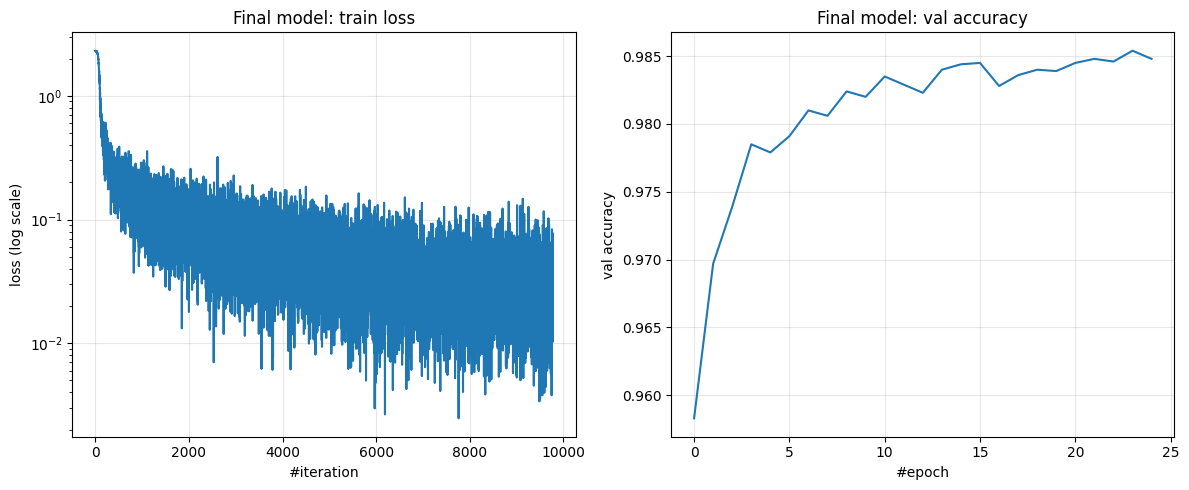

In [52]:
np.random.seed(42)

final_net = Sequential()
final_net.add(Linear(784, 256))
final_net.add(BatchNormalization(alpha=0.9)); final_net.add(ChannelwiseScaling(256))
final_net.add(ReLU()); final_net.add(Dropout(0.3))
final_net.add(Linear(256, 128))
final_net.add(BatchNormalization(alpha=0.9)); final_net.add(ChannelwiseScaling(128))
final_net.add(ReLU()); final_net.add(Dropout(0.2))
final_net.add(Linear(128, 10))
final_net.add(LogSoftMax())

criterion = ClassNLLCriterion()
optimizer_config = {"learning_rate": 3e-2, "momentum": 0.9}
optimizer_state = {}

final_loss_history, final_val_acc_history = [], []
for epoch in range(EPOCHS_FINAL):
    final_net.train()
    epoch_loss, n_batches = 0.0, 0
    for x_batch, y_batch in get_batches((X_train, Y_train), BATCH_SIZE):
        final_net.zeroGradParameters()
        pred = final_net.forward(x_batch)
        loss = criterion.forward(pred, y_batch)
        dp = criterion.backward(pred, y_batch)
        final_net.backward(x_batch, dp)
        sgd_momentum(final_net.getParameters(), final_net.getGradParameters(),
                     optimizer_config, optimizer_state)
        final_loss_history.append(loss)
        epoch_loss += loss; n_batches += 1
    optimizer_config["learning_rate"] *= 0.9   # learning rate decay (за эпоху)
    final_net.evaluate()
    val_acc = accuracy_score(final_net.forward(X_val).argmax(axis=-1), y_val)
    final_val_acc_history.append(val_acc)
    print(f"epoch {epoch+1:2d}: loss={epoch_loss/n_batches:.4f}  "
          f"val_acc={val_acc:.4f}  lr={optimizer_config['learning_rate']:.2e}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(final_loss_history)
plt.yscale("log"); plt.xlabel("#iteration"); plt.ylabel("loss (log scale)")
plt.title("Final model: train loss"); plt.grid(True, alpha=0.3)
plt.subplot(1, 2, 2); plt.plot(final_val_acc_history)
plt.xlabel("#epoch"); plt.ylabel("val accuracy")
plt.title("Final model: val accuracy"); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


Print here your accuracy on test set. It should be around 90%.

In [53]:
final_net.evaluate()
test_pred = final_net.forward(X_test)
test_acc = accuracy_score(test_pred.argmax(axis=-1), y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")


Test accuracy: 98.27%


### Comparing with PyTorch implementation
The last (and maybe the easiest step after compared to the previous tasks: build a network with the same architecture as above now with PyTorch.

You can refer to the `week0_09` or `Lab3_part2` notebooks for hints.

__Good Luck!__

In [54]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

device = "cpu"
torch.manual_seed(42)
torch.set_num_threads(1)

Xtr = torch.from_numpy(X_train); Ytr = torch.from_numpy(y_train.astype("int64"))
Xte = torch.from_numpy(X_test);  Yte = torch.from_numpy(y_test.astype("int64"))
train_dl = DataLoader(TensorDataset(Xtr, Ytr), batch_size=BATCH_SIZE, shuffle=True)

torch_net = nn.Sequential(
    nn.Linear(784, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(128, 10),
).to(device)
torch_loss = nn.CrossEntropyLoss()
torch_opt = optim.Adam(torch_net.parameters(), lr=1e-3)

TORCH_EPOCHS = 5
for epoch in range(TORCH_EPOCHS):
    torch_net.train()
    for xb, yb in train_dl:
        torch_opt.zero_grad()
        loss = torch_loss(torch_net(xb), yb)
        loss.backward(); torch_opt.step()
    torch_net.eval()
    with torch.no_grad():
        acc = (torch_net(Xte).argmax(dim=1) == Yte).float().mean().item()
    print(f"torch epoch {epoch+1}: test acc={acc:.4f}")


torch epoch 1: test acc=0.9627
torch epoch 2: test acc=0.9718
torch epoch 3: test acc=0.9761
torch epoch 4: test acc=0.9772
torch epoch 5: test acc=0.9809
